# Público adulto e paleta de cores nos sets LEGO

**Objetivo:** verificar se os sets voltados a adultos ganharam espaço no catálogo da LEGO e se a paleta de cores deles é diferente da dos sets infantis.

O dataset não informa a faixa etária, então cada set é classificado pelo seu **tema** (por exemplo, *Icons* e *Architecture* são adultos; *Duplo* e *Friends* são infantis).

Tabelas usadas: `sets`, `themes`, `inventories`, `inventory_parts` e `colors`.

## 1. Leitura dos dados

In [1]:
import sys
from contextlib import ExitStack
from functools import reduce
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import DataFrame, Window
from pyspark.sql import functions as F

# O notebook pode ser aberto da raiz do projeto ou da pasta notebooks/
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.__config__ import PATHS
from src.__main__ import create_spark_session

# Mantém a sessão aberta entre as células; ela é encerrada na última célula
_stack = ExitStack()
spark = _stack.enter_context(create_spark_session("Lego-Publico-Cores"))
spark.sparkContext.setLogLevel("ERROR")

def ler(nome: str) -> DataFrame:
    return spark.read.parquet(str(PATHS.data / f"{nome}.parquet"))

sets = ler("sets")
themes = ler("themes").withColumn("parent_id", F.col("parent_id").cast("long"))
colors = ler("colors")
inventories = ler("inventories")
inventory_parts = ler("inventory_parts")

## 2. Classificação dos sets por público

Os temas formam uma árvore (ex.: *Creator Expert* fica dentro de *Creator*), então cada set é classificado olhando todos os temas acima dele:

- **Adulto:** pertence a uma linha vendida para adultos (Icons, UCS, Architecture, Botanicals…)
- **Criança:** pertence a uma linha infantil ou pré-escolar (Duplo, Juniors, Friends…)
- **Geral/família:** todo o resto (City, Star Wars, Technic, Ninjago…)

Livros, acessórios, brindes e minifiguras avulsas ficam de fora, assim como sets sem peças e lançamentos após 2025.

In [2]:
TEMAS_ADULTO = [
    "Icons", "Creator Expert", "Modular Buildings", "Ultimate Collector Series",
    "Architecture", "LEGO Art", "Botanicals", "LEGO Ideas and CUUSOO",
    "Sculptures", "BrickLink Designer Program", "Editions",
]
TEMAS_CRIANCA = [
    "Duplo", "Primo", "Quatro", "Juniors", "4 Juniors", "Fabuland", "Belville",
    "Friends", "Gabby's Dollhouse", "Bluey", "Dreamzzz", "Scala", "Clikits",
    "Early Creator",
]
RAIZES_FORA = [
    "Gear", "Books", "Promotional", "Collectible Minifigures", "Service Packs",
    "Bulk Bricks", "Educational and Dacta", "Games", "LEGO Brand Store",
]

# Sobe a árvore de temas nível por nível até chegar às raízes
pais = themes.select(F.col("id").alias("parent_id"), "name",
                     F.col("parent_id").alias("proximo_pai"))
nivel = themes.select(F.col("id").alias("theme_id"), "name", "parent_id")
niveis = [nivel]
while not nivel.filter(F.col("parent_id").isNotNull()).isEmpty():
    nivel = (nivel.filter(F.col("parent_id").isNotNull())
             .select("theme_id", "parent_id")
             .join(pais, "parent_id")
             .select("theme_id", "name", F.col("proximo_pai").alias("parent_id")))
    niveis.append(nivel)
ancestrais = reduce(DataFrame.unionByName, niveis)

def lista(nomes):
    return F.array(*[F.lit(n) for n in nomes])

temas_classificados = (
    ancestrais.groupBy("theme_id")
    .agg(F.collect_set("name").alias("cadeia"),
         F.max(F.when(F.col("parent_id").isNull(), F.col("name"))).alias("tema_raiz"))
    .withColumn(
        "grupo",
        F.when(F.arrays_overlap("cadeia", lista(TEMAS_ADULTO)), "Adulto")
        .when(F.arrays_overlap("cadeia", lista(TEMAS_CRIANCA)), "Criança")
        .when(F.col("tema_raiz").isin(RAIZES_FORA), "Fora")
        .otherwise("Geral/família"))
)

sets_cls = (
    sets.join(temas_classificados, "theme_id")
    .filter((F.col("num_parts") > 0) & (F.col("year") <= 2025) & (F.col("grupo") != "Fora"))
    .withColumn("decada", (F.floor(F.col("year") / 10) * 10).cast("int"))
    .cache()
)
print(f"{sets_cls.count():,} sets classificados")

14,933 sets classificados


## 3. Participação do público adulto

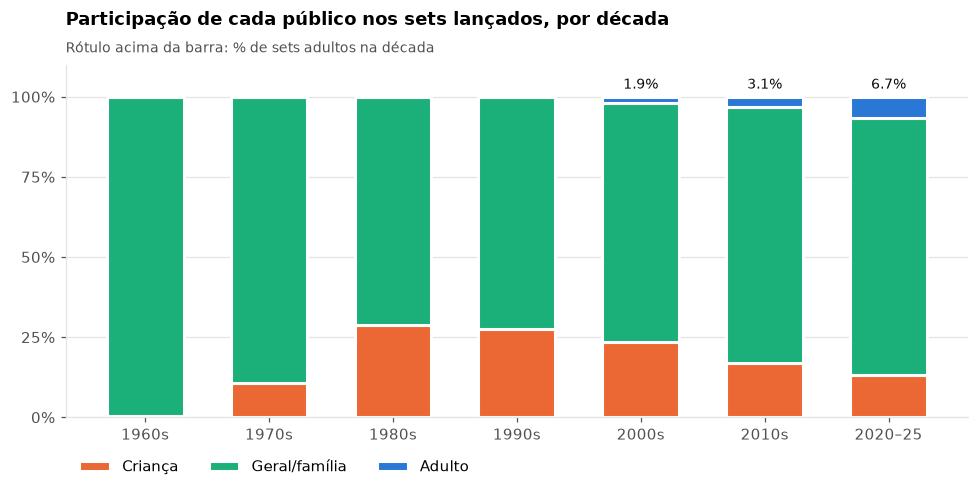

In [3]:
GRUPOS = ["Criança", "Geral/família", "Adulto"]
CORES_GRUPO = {"Adulto": "#2a78d6", "Criança": "#eb6834", "Geral/família": "#1baf7a"}
TINTA, TINTA_2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": GRADE,
    "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def estilo(ax, grade="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis=grade, color=GRADE, linewidth=0.8)
    ax.set_axisbelow(True)

por_decada = (sets_cls.groupBy("decada", "grupo").count()
              .withColumn("pct", F.col("count") / F.sum("count").over(Window.partitionBy("decada")) * 100)
              .toPandas()
              .pivot(index="decada", columns="grupo", values="pct")
              .fillna(0)[GRUPOS])
por_decada = por_decada.loc[por_decada.index >= 1960]
rotulos = [f"{d}s" if d < 2020 else "2020–25" for d in por_decada.index]

fig, ax = plt.subplots(figsize=(9, 4.6))
base = pd.Series(0.0, index=por_decada.index)
for g in GRUPOS:
    ax.bar(rotulos, por_decada[g], bottom=base, color=CORES_GRUPO[g], label=g,
           width=0.62, edgecolor="white", linewidth=2)
    base += por_decada[g]
for x, v in zip(rotulos, por_decada["Adulto"]):
    if v >= 1:
        ax.text(x, 101.5, f"{v:.1f}%", ha="center", va="bottom", fontsize=9, color=TINTA)
estilo(ax)
ax.set_ylim(0, 110)
ax.set_yticks(range(0, 101, 25), [f"{t}%" for t in range(0, 101, 25)])
ax.set_title("Participação de cada público nos sets lançados, por década", pad=26)
ax.text(0, 1.035, "Rótulo acima da barra: % de sets adultos na década", transform=ax.transAxes,
        fontsize=9, color=TINTA_2)
ax.legend(ncols=3, frameon=False, loc="upper left", bbox_to_anchor=(0, -0.08))
plt.tight_layout()
plt.show()

Até os anos 1990 não havia sets adultos. A fatia surge nos anos 2000 (1,9%), sobe para 3,1% nos 2010 e chega a **6,7% em 2020–2025**, enquanto a fatia infantil cai de cerca de 28% para 13%.

Para checar se esse resultado depende da classificação por tema, comparamos com um critério independente: **sets com 1.000 peças ou mais**. Os níveis não precisam bater, mas a tendência deve ser a mesma.

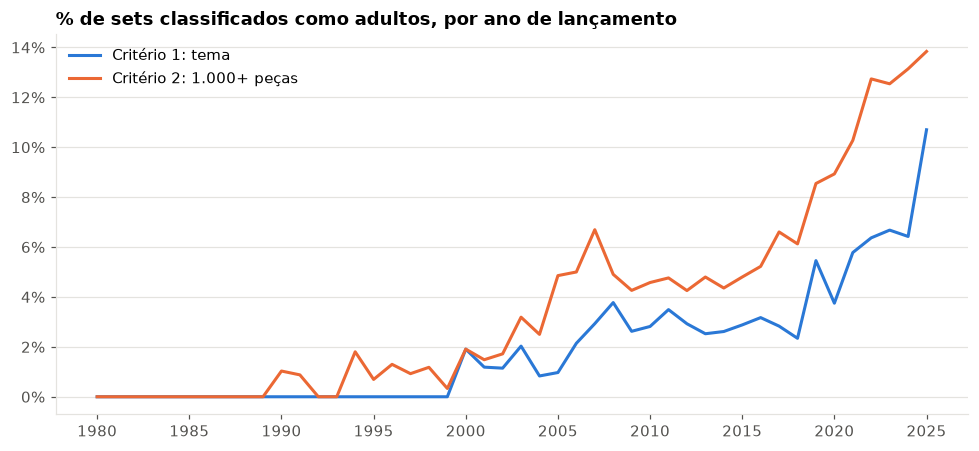

In [4]:
por_ano = (sets_cls.filter(F.col("year") >= 1980).groupBy("year")
           .agg((F.avg((F.col("grupo") == "Adulto").cast("int")) * 100).alias("Critério 1: tema"),
                (F.avg((F.col("num_parts") >= 1000).cast("int")) * 100).alias("Critério 2: 1.000+ peças"))
           .orderBy("year").toPandas().set_index("year"))

fig, ax = plt.subplots(figsize=(9, 4.2))
for col, cor in zip(por_ano.columns, ["#2a78d6", "#eb6834"]):
    ax.plot(por_ano.index, por_ano[col], color=cor, linewidth=2, label=col)
estilo(ax)
ax.set_xticks(range(1980, 2026, 5))
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_title("% de sets classificados como adultos, por ano de lançamento")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

As duas curvas sobem juntas a partir dos anos 2000 e aceleram depois de 2018. O critério de peças fica mais alto porque também pega Technic e Star Wars grandes, mas a tendência é a mesma.

## 4. Paleta de cores por público

Usamos as peças de cada set (versão mais recente do inventário, sem peças sobressalentes), ponderadas pela quantidade. Só entram sets de **2005 em diante**, para comparar paletas da mesma época.

Consideramos **neutras** as cores preto, branco, cinzas, marrons e tan.

In [5]:
NEUTRAS = ["Black", "White", "Light Bluish Gray", "Dark Bluish Gray", "Light Gray",
           "Dark Gray", "Tan", "Dark Tan", "Reddish Brown", "Dark Brown"]

cores = (colors.filter(~F.col("id").isin(-1, 9999))
         .select(F.col("id").alias("color_id"), F.col("name").alias("cor"), "rgb")
         .withColumn("neutra", F.col("cor").isin(NEUTRAS)))

ultima_versao = (inventories
                 .withColumn("pos", F.row_number().over(Window.partitionBy("set_num").orderBy(F.desc("version"))))
                 .filter("pos = 1").select(F.col("id").alias("inventory_id"), "set_num"))

pecas = (inventory_parts.filter(~F.col("is_spare"))
         .join(ultima_versao, "inventory_id")
         .join(sets_cls.filter(F.col("year") >= 2005).select("set_num", "grupo", "year"), "set_num")
         .join(F.broadcast(cores), "color_id")
         .select("set_num", "grupo", "year", "cor", "rgb", "neutra", "quantity")
         .cache())

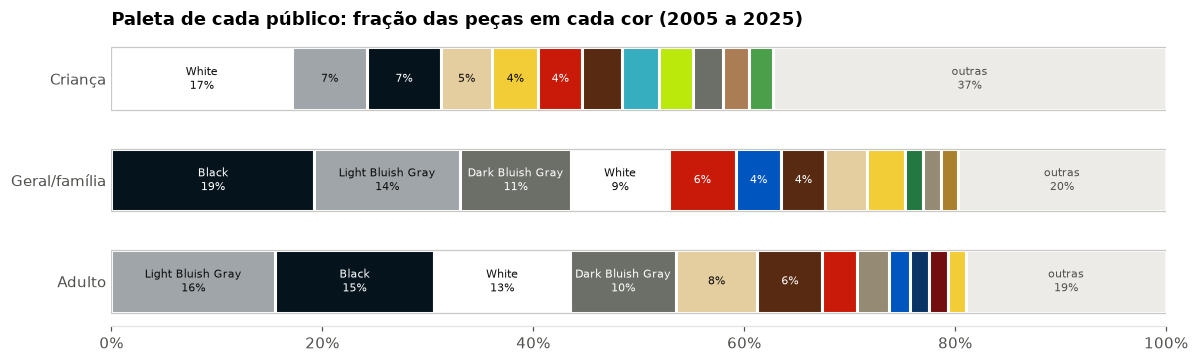

In [6]:
def cor_texto(rgb):
    r, g, b = (int(rgb[i:i + 2], 16) for i in (0, 2, 4))
    return "white" if 0.299 * r + 0.587 * g + 0.114 * b < 140 else TINTA

participacao = (pecas.groupBy("grupo", "cor", "rgb").agg(F.sum("quantity").alias("qtd"))
                .withColumn("pct", F.col("qtd") / F.sum("qtd").over(Window.partitionBy("grupo")) * 100)
                .toPandas())

fig, ax = plt.subplots(figsize=(11, 3.4))
for y, g in enumerate(GRUPOS[::-1]):
    d = participacao[participacao.grupo == g].nlargest(12, "pct")
    esquerda = 0.0
    for _, linha in d.iterrows():
        ax.barh(y, linha.pct, left=esquerda, color=f"#{linha.rgb}", height=0.62,
                edgecolor="white", linewidth=2)
        if linha.pct >= 4:
            rotulo = f"{linha.cor}\n{linha.pct:.0f}%" if linha.pct >= 9 else f"{linha.pct:.0f}%"
            ax.text(esquerda + linha.pct / 2, y, rotulo, ha="center",
                    va="center", fontsize=7.5, color=cor_texto(linha.rgb))
        esquerda += linha.pct
    ax.barh(y, 100 - esquerda, left=esquerda, color="#ecebe7", height=0.62, edgecolor="white", linewidth=2)
    ax.text(esquerda + (100 - esquerda) / 2, y, f"outras\n{100 - esquerda:.0f}%", ha="center",
            va="center", fontsize=7.5, color=TINTA_2)
    # Contorno da faixa, para o segmento branco não sumir no fundo
    ax.barh(y, 100, height=0.62, fill=False, edgecolor="#c9c8c3", linewidth=0.8)
ax.set_yticks(range(3), GRUPOS[::-1])
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title("Paleta de cada público: fração das peças em cada cor (2005 a 2025)")
plt.tight_layout()
plt.show()

Nos sets adultos e de público geral predominam cinzas, preto e branco; nos adultos também aparecem tan e marrom. Nos infantis, além do branco, ganham espaço cores vivas como amarelo, vermelho, azul-claro e verde-limão.

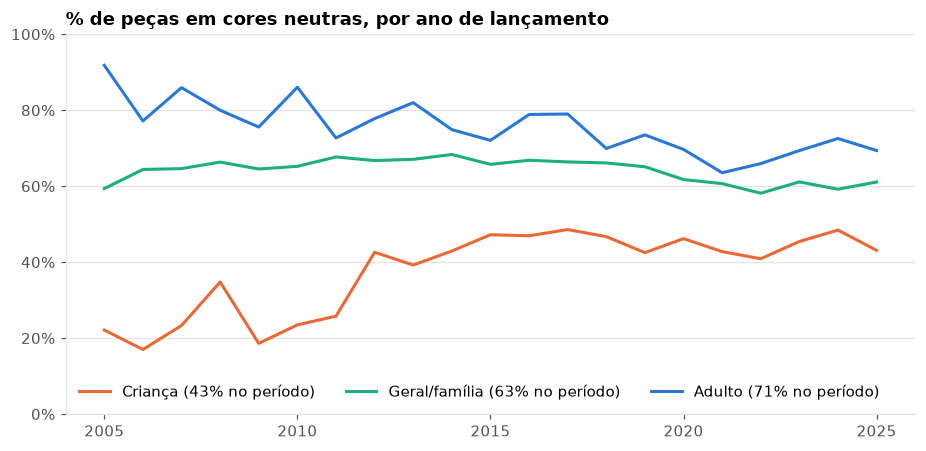

In [7]:
pct_neutras = (F.sum(F.when(F.col("neutra"), F.col("quantity")).otherwise(0)) / F.sum("quantity") * 100).alias("pct")
neutras_total = pecas.groupBy("grupo").agg(pct_neutras).toPandas().set_index("grupo")["pct"]
neutras_ano = (pecas.groupBy("year", "grupo").agg(pct_neutras)
               .toPandas().pivot(index="year", columns="grupo", values="pct")[GRUPOS])

fig, ax = plt.subplots(figsize=(9, 4.2))
for g in GRUPOS:
    ax.plot(neutras_ano.index, neutras_ano[g], color=CORES_GRUPO[g], linewidth=2,
            label=f"{g} ({neutras_total[g]:.0f}% no período)")
estilo(ax)
ax.set_ylim(0, 100)
ax.set_xticks(range(2005, 2026, 5))
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_title("% de peças em cores neutras, por ano de lançamento")
ax.legend(frameon=False, ncols=3, loc="lower left")
plt.tight_layout()
plt.show()

Os sets adultos têm mais peças neutras que os infantis em todos os anos desde 2005 (71% contra 43% no período). A diferença diminuiu com o tempo, mas a ordem entre os grupos nunca se inverte.

## 5. Conclusões

**1. O público adulto cresceu.** Os sets adultos foram de 0% dos lançamentos até os anos 1990 para 6,7% em 2020–2025. O critério de 1.000+ peças mostra a mesma tendência, então o resultado não depende da nossa classificação por tema.

**2. A paleta adulta é mais sóbria.** Nos sets de 2005 a 2025, 71% das peças dos sets adultos são de cores neutras, contra 43% nos infantis. Os adultos usam mais cinza, preto, tan e marrom; os infantis, mais cores vivas como amarelo, azul-claro, verde-limão e rosa. Essa diferença se mantém em todos os anos.

**Limitações:** o dataset não informa a faixa etária, então a classificação depende dos temas escolhidos. Temas mistos, como Technic e Star Wars, ficaram em "geral/família".

In [8]:
# Encerra a sessão Spark
_stack.close()